# 04 — SAM/Vicon validation

Main local working notebook. Reuses `src.comparison_engine` for metrics and `src.plotting` for visualization. **Already-aligned CSVs with embedded Vicon** are legacy exploratory comparisons, not independent verification of synchronization.

In [1]:
import sys
print(sys.executable)

import numpy as np
print("NumPy:", np.__version__)

/Users/thomasjohnson/markerless/markerless_sam/.venv/bin/python
NumPy: 2.2.6


In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Run Jupyter from the repository or notebooks/ folder")
sys.path.insert(0, str(ROOT))
DATA = ROOT / "lunge_sam_out"
RESULTS = ROOT / "results"
print(ROOT, DATA.exists())

/Users/thomasjohnson/markerless/markerless_sam True


In [ ]:
from scipy.signal import correlate, correlation_lags

def diagnose_joint(df, joint="knee", method="geo",
                   static_window_ms=1500, max_lag_ms=500):

    t = df["time_ms_aligned"].to_numpy(dtype=float)
    v = df[f"vicon_{joint}_flex"].to_numpy(dtype=float)
    s = df[f"r_{joint}_flex_{method}"].to_numpy(dtype=float)

    valid = np.isfinite(t) & np.isfinite(v) & np.isfinite(s)
    t, v, s = t[valid], v[valid], s[valid]

    static = t <= t[0] + static_window_ms

    baseline_v = np.median(v[static])
    baseline_s = np.median(s[static])

    dt = np.median(np.diff(t))

    # Diagnostic lag only: uniform time grid and zero-mean signals.
    grid = np.arange(t[0], t[-1], dt)
    vg = np.interp(grid, t, v)
    sg = np.interp(grid, t, s)

    a = vg - np.mean(vg)
    b = sg - np.mean(sg)

    corr = correlate(a, b, mode="full")
    lags = correlation_lags(len(a), len(b), mode="full")

    allowed = np.abs(lags * dt) <= max_lag_ms
    best_lag = lags[allowed][np.argmax(corr[allowed])] * dt

    return {
        "joint": joint,
        "method": method,
        "baseline_offset_deg": baseline_v - baseline_s,
        "vicon_rom_deg": np.ptp(v),
        "sam_rom_deg": np.ptp(s),
        "rom_difference_deg": np.ptp(s) - np.ptp(v),
        "diagnostic_lag_ms": best_lag,
    }


rows = [
    diagnose_joint(df, joint, method)
    for joint in ("hip", "knee", "ankle")
    for method in ("geo", "euler")
    if f"r_{joint}_flex_{method}" in df
]

display(pd.DataFrame(rows).round(2))

In [3]:
from src.comparison_engine import compare_angles
from src.plotting import plot_joint_overlays, plot_joint_errors, plot_camera_comparison
files = sorted(DATA.glob("*_joint_angles.csv"))
print(f"Found {len(files)} joint-angle CSV files")
for i, f in enumerate(files):
    print(i, f.name)

Found 21 joint-angle CSV files
0 s10_lunge_cam0_joint_angles.csv
1 s10_lunge_cam1_joint_angles.csv
2 s10_lunge_cam2_joint_angles.csv
3 s11_lunge_cam0_joint_angles.csv
4 s11_lunge_cam1_joint_angles.csv
5 s11_lunge_cam2_joint_angles.csv
6 s1_lunge_cam0_joint_angles.csv
7 s1_lunge_cam1_joint_angles.csv
8 s1_lunge_cam2_joint_angles.csv
9 s2_lunge_cam0_joint_angles.csv
10 s2_lunge_cam1_joint_angles.csv
11 s2_lunge_cam2_joint_angles.csv
12 s6_lunge_cam0_joint_angles.csv
13 s6_lunge_cam1_joint_angles.csv
14 s6_lunge_cam2_joint_angles.csv
15 s8_lunge_cam0_joint_angles.csv
16 s8_lunge_cam1_joint_angles.csv
17 s8_lunge_cam2_joint_angles.csv
18 s9_lunge_cam0_joint_angles.csv
19 s9_lunge_cam1_joint_angles.csv
20 s9_lunge_cam2_joint_angles.csv


In [5]:
SELECTED = 0
if files:
    csv_path = files[SELECTED]
    df = pd.read_csv(csv_path)
    display(df.head())
    print("Columns:", list(df.columns))
else:
    df = None
    print("Export/download pre-aligned joint angle CSV files into lunge_sam_out/")

,time_ms_aligned,vicon_ankle_flex,vicon_knee_flex,vicon_hip_flex,r_ankle_flex_euler,r_knee_flex_euler,r_hip_flex_euler,r_ankle_flex_geo,r_knee_flex_geo,r_hip_flex_geo
0,1130.000000,84.059316,1.492938,-20.721633,83.111613,0.653075,-22.758975,77.348738,9.378060,2.483200
1,1213.298611,83.870907,1.821919,-20.755040,83.333225,0.818469,-22.765931,77.704418,9.504488,2.615372
2,1296.597222,83.668130,1.993158,-20.669194,83.484677,0.977822,-22.701146,77.831983,9.476616,2.712948
3,1379.895833,83.561784,1.874983,-20.403660,83.579564,1.129205,-22.578276,77.799108,9.362863,2.787766
4,1463.194444,83.558961,1.600903,-20.085845,83.631474,1.270713,-22.411132,77.673469,9.231649,2.851669


Columns: ['time_ms_aligned', 'vicon_ankle_flex', 'vicon_knee_flex', 'vicon_hip_flex', 'r_ankle_flex_euler', 'r_knee_flex_euler', 'r_hip_flex_euler', 'r_ankle_flex_geo', 'r_knee_flex_geo', 'r_hip_flex_geo']


In [6]:
if df is not None:
    import re
    match = re.match(r"(s[0-9]+)_lunge_(cam[0-9]+)_joint_angles[.]csv", csv_path.name, re.I)
    subject, camera = (match.group(1).upper(), match.group(2)) if match else ("unknown", "unknown")
    out_dir = RESULTS / subject / "lunge_01" / camera
    if "time_ms_aligned" not in df or not any(col.startswith("vicon_") for col in df):
        raise ValueError("Expected pre-aligned CSV with embedded Vicon. For raw inputs use independent sync JSON and Vicon CSV.")
    metrics = compare_angles(csv_path, out_dir, subject=subject, trial="lunge_01", camera=camera, allow_legacy_embedded_reference=True, plot=False)
    display(metrics)

,subject,trial,camera,joint,method,reference_origin,sync_method,sync_shift_ms,n_samples,rmse_raw_deg,mae_raw_deg,bias_deg,pearson_r,rom_error_deg,peak_error_deg,peak_time_error_ms
0,S10,lunge_01,cam0,hip,geo,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,139,31.194320,27.829031,25.337675,0.842565,-2.440788,22.482425,-333.194444
1,S10,lunge_01,cam0,hip,euler,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,139,44.980168,32.458238,-6.129565,-0.117811,-19.924696,-20.120343,-1999.166667
2,S10,lunge_01,cam0,knee,geo,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,139,31.019691,22.834946,16.381355,0.718175,22.250587,31.382837,1166.180556
3,S10,lunge_01,cam0,knee,euler,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,139,25.059000,16.959968,5.563649,0.721975,11.034001,6.084806,-2082.465278
4,S10,lunge_01,cam0,ankle,geo,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,139,12.725571,10.252021,-6.859843,0.529115,-31.734618,-12.354892,-3665.138889
5,S10,lunge_01,cam0,ankle,euler,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,139,22.122305,15.395050,-14.432229,0.102849,-15.516072,-26.109703,-3665.138889


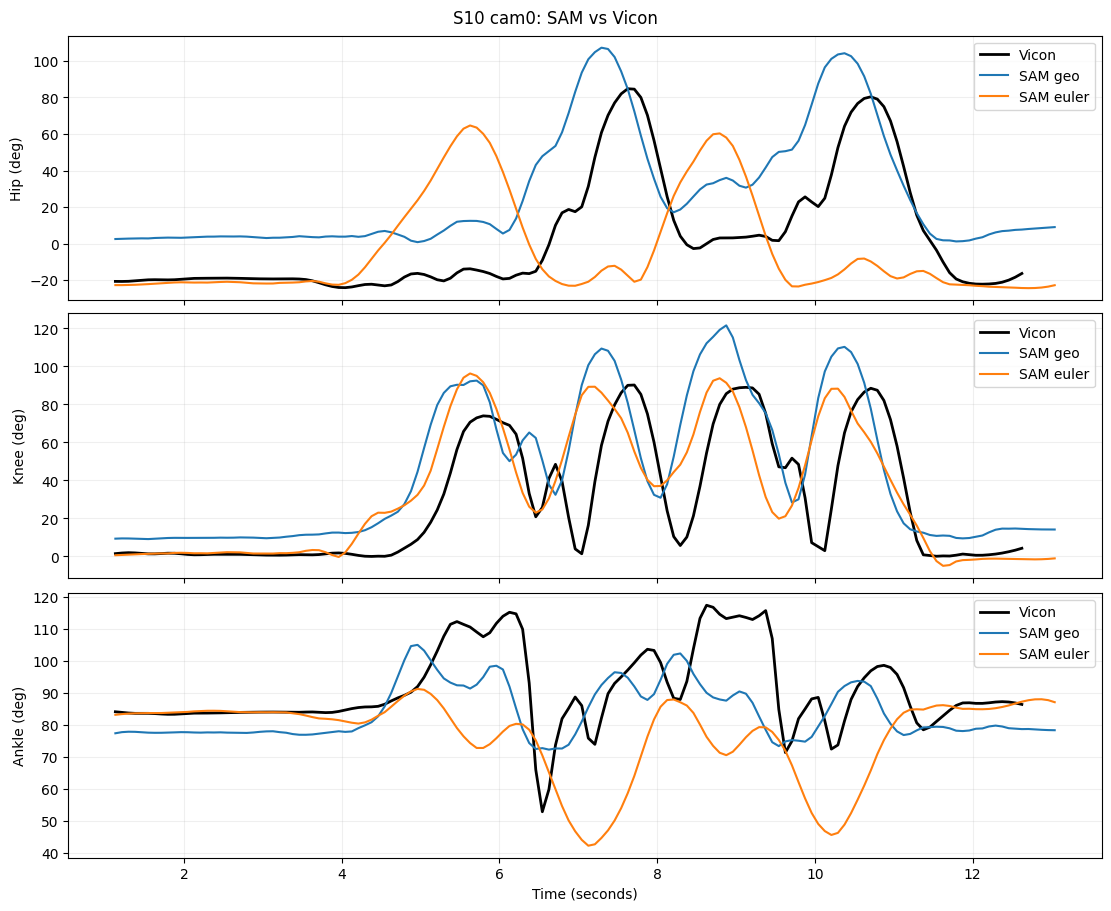

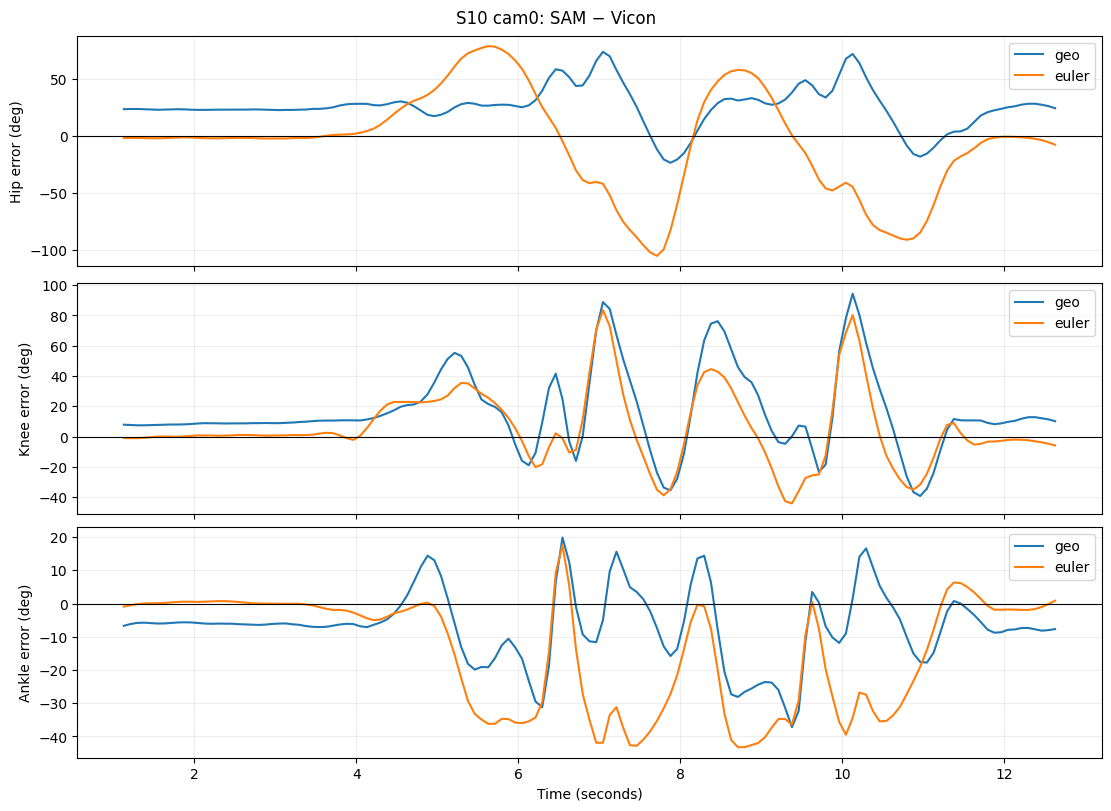

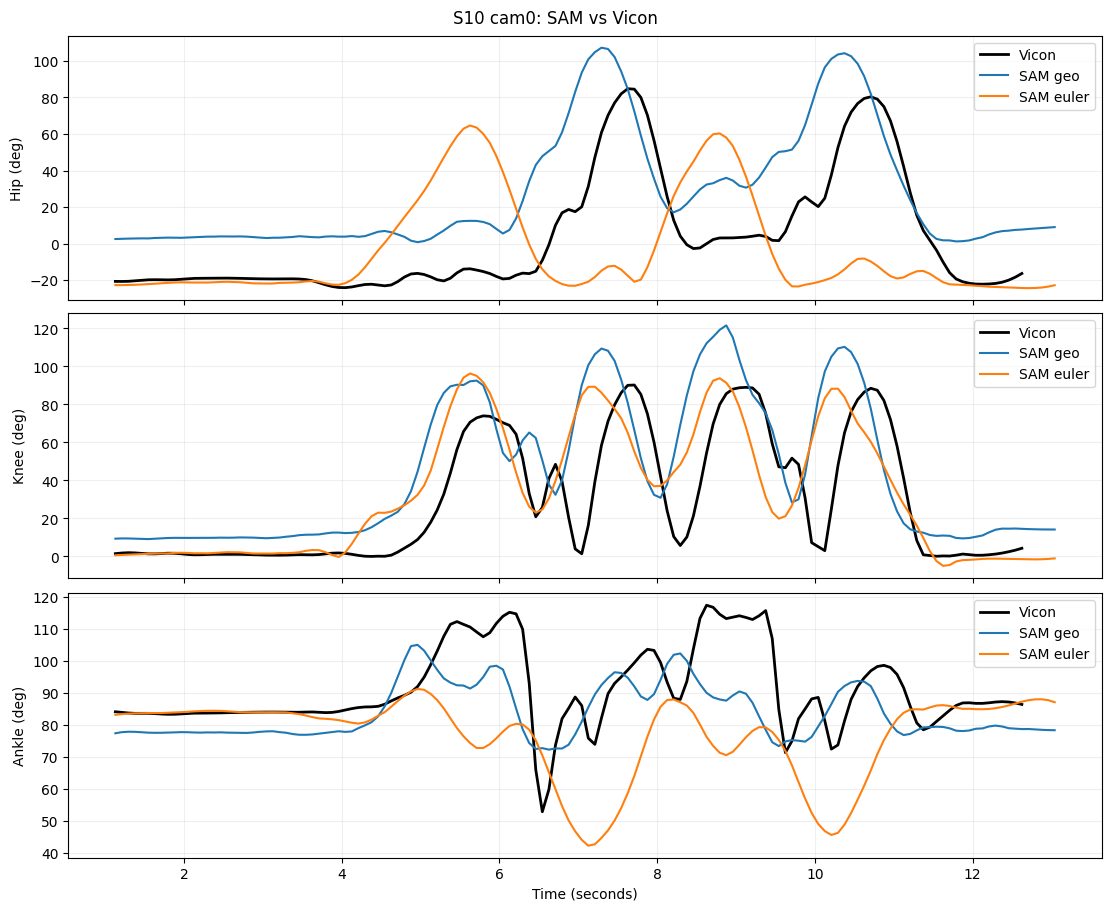

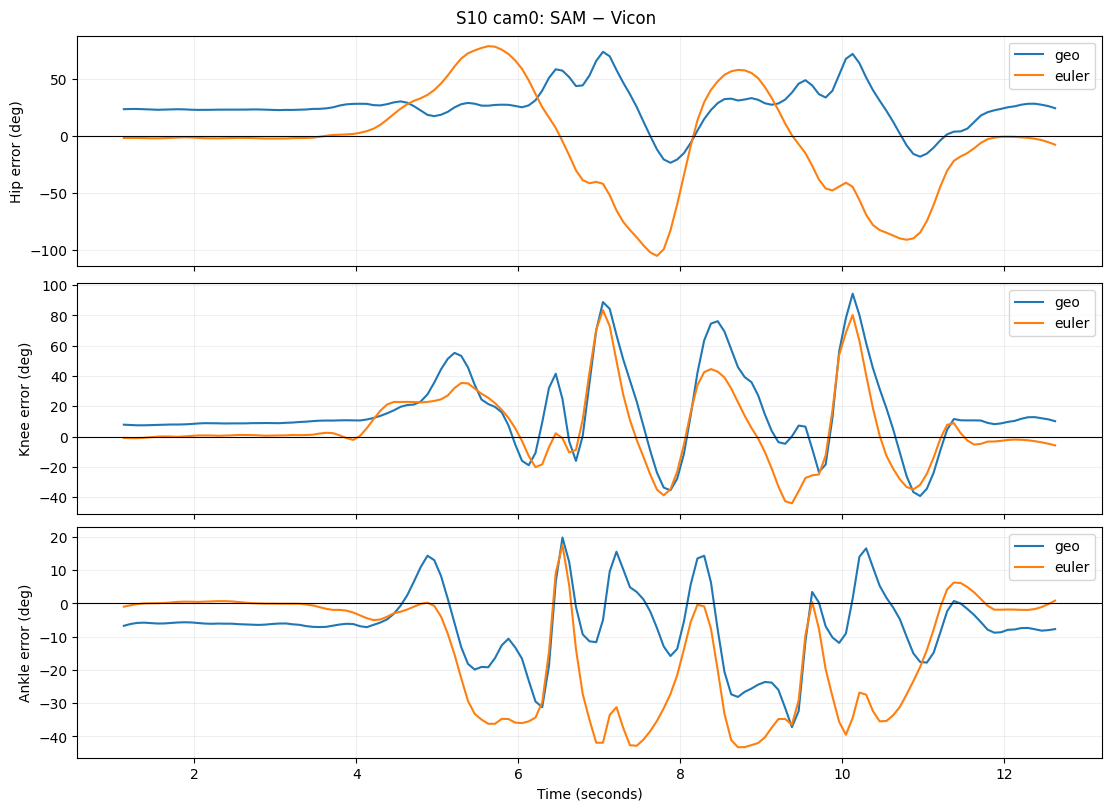

In [7]:
if df is not None:
    display(plot_joint_overlays(df, title=f"{subject} {camera}: SAM vs Vicon"))
    display(plot_joint_errors(df, title=f"{subject} {camera}: SAM − Vicon"))

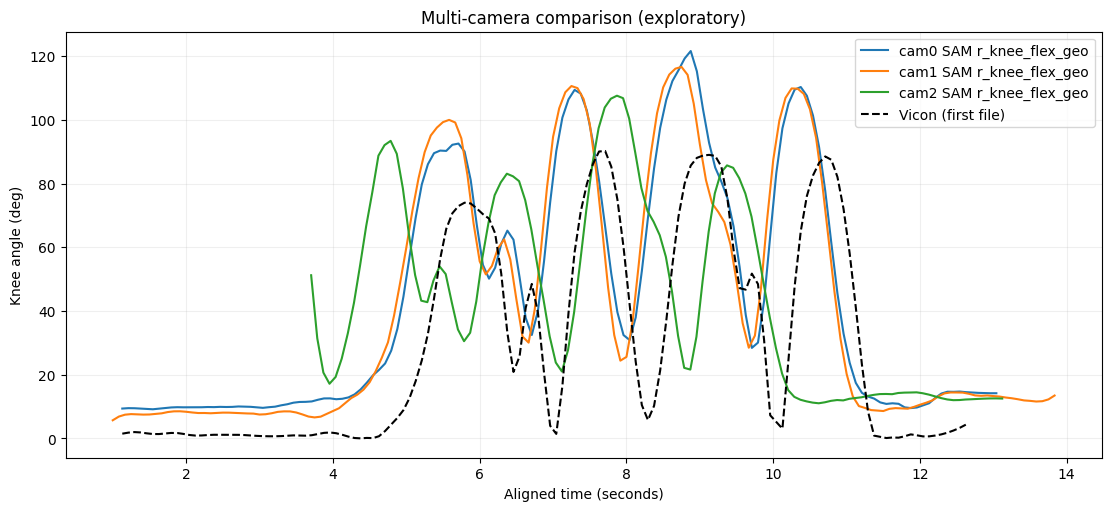

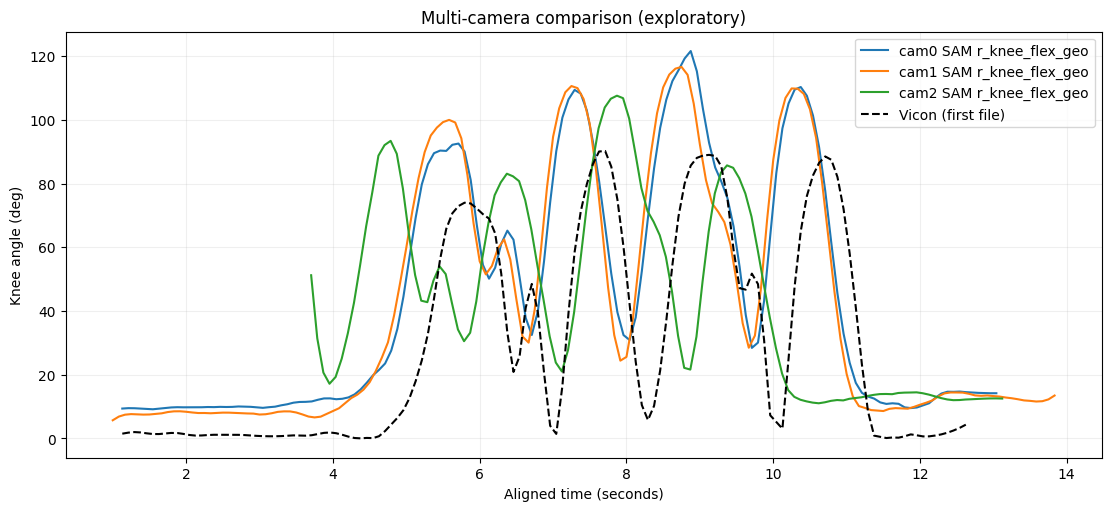

In [8]:
if len(files) >= 2:
    first_subject = files[0].name.split("_")[0]
    same_subject = [f for f in files if f.name.startswith(first_subject + "_")]
    if len(same_subject) >= 2:
        camera_frames = {p.name.split("_")[2]: pd.read_csv(p) for p in same_subject}
        display(plot_camera_comparison(camera_frames, joint="knee", method="geo"))

### Scientific checks
The imported CSVs may already be filtered and interpolated. Do not shift again. Document anatomical signs/definitions, and separately report raw versus independently calibrated error. For real independent validation, use raw SAM `time_ms`, reviewed `sync.json`, and standalone Vicon `time_ms`/angle CSV. Aggregate inference across reps/trials/subjects rather than treating all samples as independent.